# Q-CHIPP: original-circuit verification and MerLin adaptation

Peters et al., *Science Advances* (2026), DOI 10.1126/sciadv.aec3824.

This notebook walks through the reproduction on the published DataS1 release: the data splits, the source gate QCNN, the photonic MerLin adaptation, the comparison against classical controls, and the two-head AND predictor. It is a reproducibility study, not a clinical validation.

In [1]:
import importlib.metadata
import json
import os
import sys
from pathlib import Path

import pandas as pd
import torch

REPO_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'implementation.py').exists()
)
PROJECT = REPO_ROOT / 'papers' / 'QCHIPP'
for import_root in (REPO_ROOT, PROJECT):
    if str(import_root) not in sys.path:
        sys.path.insert(0, str(import_root))
torch.set_num_threads(1)
print('MerLin', importlib.metadata.version('merlinquantum'), '| Torch', torch.__version__)


MerLin 0.4.2 | Torch 2.10.0+cu128


## DataS1 and the released splits

DataS1 is downloaded from Europe PMC on first use and verified by SHA-256 (see the README). Binding uses residue positions 2, 4, 5, 9; binder-only immunogenicity uses 3, 5, 6, 7. The released test sets have 1000 rows, not the 50/100 described in the manuscript. The binding test row DLPLIIQRL has no assay truth and is excluded. The residue encoding uses the source's sorted category ranks fitted over train and test together; this transductive vocabulary is disclosed, not hidden.

In [2]:
from lib.data import load_task

populations = {
    task: load_task({'seed': 49, 'dataset': {'task': task, 'positions': positions}})
    for task, positions in [('binding', [2, 4, 5, 9]), ('immunogenic', [3, 5, 6, 7])]
}
pd.DataFrame(
    [
        {
            'task': task,
            'train': len(d['train']['targets']),
            'test': len(d['test']['targets']),
            'excluded': d['excluded_missing_assay'],
            'sha256': d['source_sha256'][:12],
        }
        for task, d in populations.items()
    ]
)


,task,train,test,excluded,sha256
0,binding,150,999,[DLPLIIQRL],2b91dde1046d
1,immunogenic,300,1000,[],2b91dde1046d


## Source circuit and source loss

`lib/gate.py` is a PyTorch statevector translation of the authors' Qiskit pyramid; `tests/test_gate.py` checks it against the IBM v1.0.0 circuits to 2e-12. The score is s = 0.5⟨Z⟩ on logical wire n/2, with (2,1)-QRAC bit pairing and unshared pyramid weights. The released loss is mean[-y log2(max(s, 1e-10))], not a Bernoulli BCE; the corrected variant uses the physical probability p = 0.5 + s. See `LOSS_SEMANTICS.md`. The predictions below come from an **untrained** model and only show the interface.

In [3]:
from lib.gate import GateQCNN

gate = GateQCNN(seed=49)
with torch.no_grad():
    gate_probability = gate.probabilities(populations['binding']['test']['bits'][:4])
print('Gate parameters', sum(p.numel() for p in gate.parameters()))
pd.DataFrame(
    {
        'peptide': populations['binding']['test']['peptides'][:4],
        'untrained_positive_probability': gate_probability.numpy(),
    }
)


Gate parameters 81


,peptide,untrained_positive_probability
0,AAAAGWQTL,0.446876
1,AAAGDKLSL,0.486628
2,AAFAHFPEL,0.463937
3,AAITDAAVA,0.515746


## Photonic adaptation

The primary model uses two stages of local, shared seven-mode / two-photon filters with input state [1, 0, 0, 1, 0, 0, 0] and full Fock probabilities (28 outcomes). The seventh mode is not encoded, so the six input phases are measured against a physical reference. The legacy six-mode model encodes every mode and cannot distinguish residue codes that differ by a common phase; it is kept as a labelled ablation. Classical three-feature bottlenecks replace coherent pooling, so the translation is partial. Parameters: 168 optical + 178 classical = 346, against 350 for the matched MLP (hidden width 17).

In [4]:
from lib.classical import ClassicalQCNN
from lib.photonic import ReferencePhotonicQCNN

torch.manual_seed(49)
optical = ReferencePhotonicQCNN().eval()
classical = ClassicalQCNN(hidden=17)
with torch.no_grad():
    logits = optical(populations['binding']['test']['bits'][:4])
print('Photonic parameters', sum(p.numel() for p in optical.parameters()))
print('Classical parameters', sum(p.numel() for p in classical.parameters()))


Photonic parameters 346
Classical parameters 350


## Comparison with fair controls

`results/comparison_summary.json` aggregates the 62 reported runs: 36 in the main comparison, 12 one-hot controls, 12 reference-model runs and 2 label-convention sensitivity runs. Three seeds measure optimisation variation on one release split, not independent-cohort uncertainty.

In [5]:
report = json.loads((PROJECT / 'results' / 'comparison_summary.json').read_text())
pd.DataFrame(
    [
        {
            'task': r['task'],
            'model': r['model'],
            'parameters': r['parameters']['total'],
            'F1_mean': r['f1']['mean'],
            'F1_SD': r['f1']['sample_sd'],
            'AUROC': r['auroc']['mean'],
        }
        for r in report['rows']
    ]
)


,task,model,parameters,F1_mean,F1_SD,AUROC
0,binding,gate_source,81.0,0.746570,0.014313,0.774274
1,binding,gate_corrected,81.0,0.757671,0.008594,0.835014
2,binding,merlin,256.0,0.727107,0.028194,0.786760
3,binding,classical,250.0,0.736496,0.034234,0.802391
4,binding,rf,NaN,0.808514,0.005391,0.882988
5,binding,logistic,21.0,0.812741,0.000000,0.871062
6,immunogenic,gate_source,81.0,0.511974,0.039263,0.551505
7,immunogenic,gate_corrected,81.0,0.509847,0.014775,0.560707
8,immunogenic,merlin,256.0,0.524386,0.028379,0.542043
9,immunogenic,classical,250.0,0.533727,0.063483,0.567023


## Figures and the supplied-affinity diagnostic

The figures are regenerated by `utils/render_results.py` from the run artifacts. The affinity diagnostic scores the externally trained affinity ranks shipped in DataS1; it is not a parameter-matched baseline.

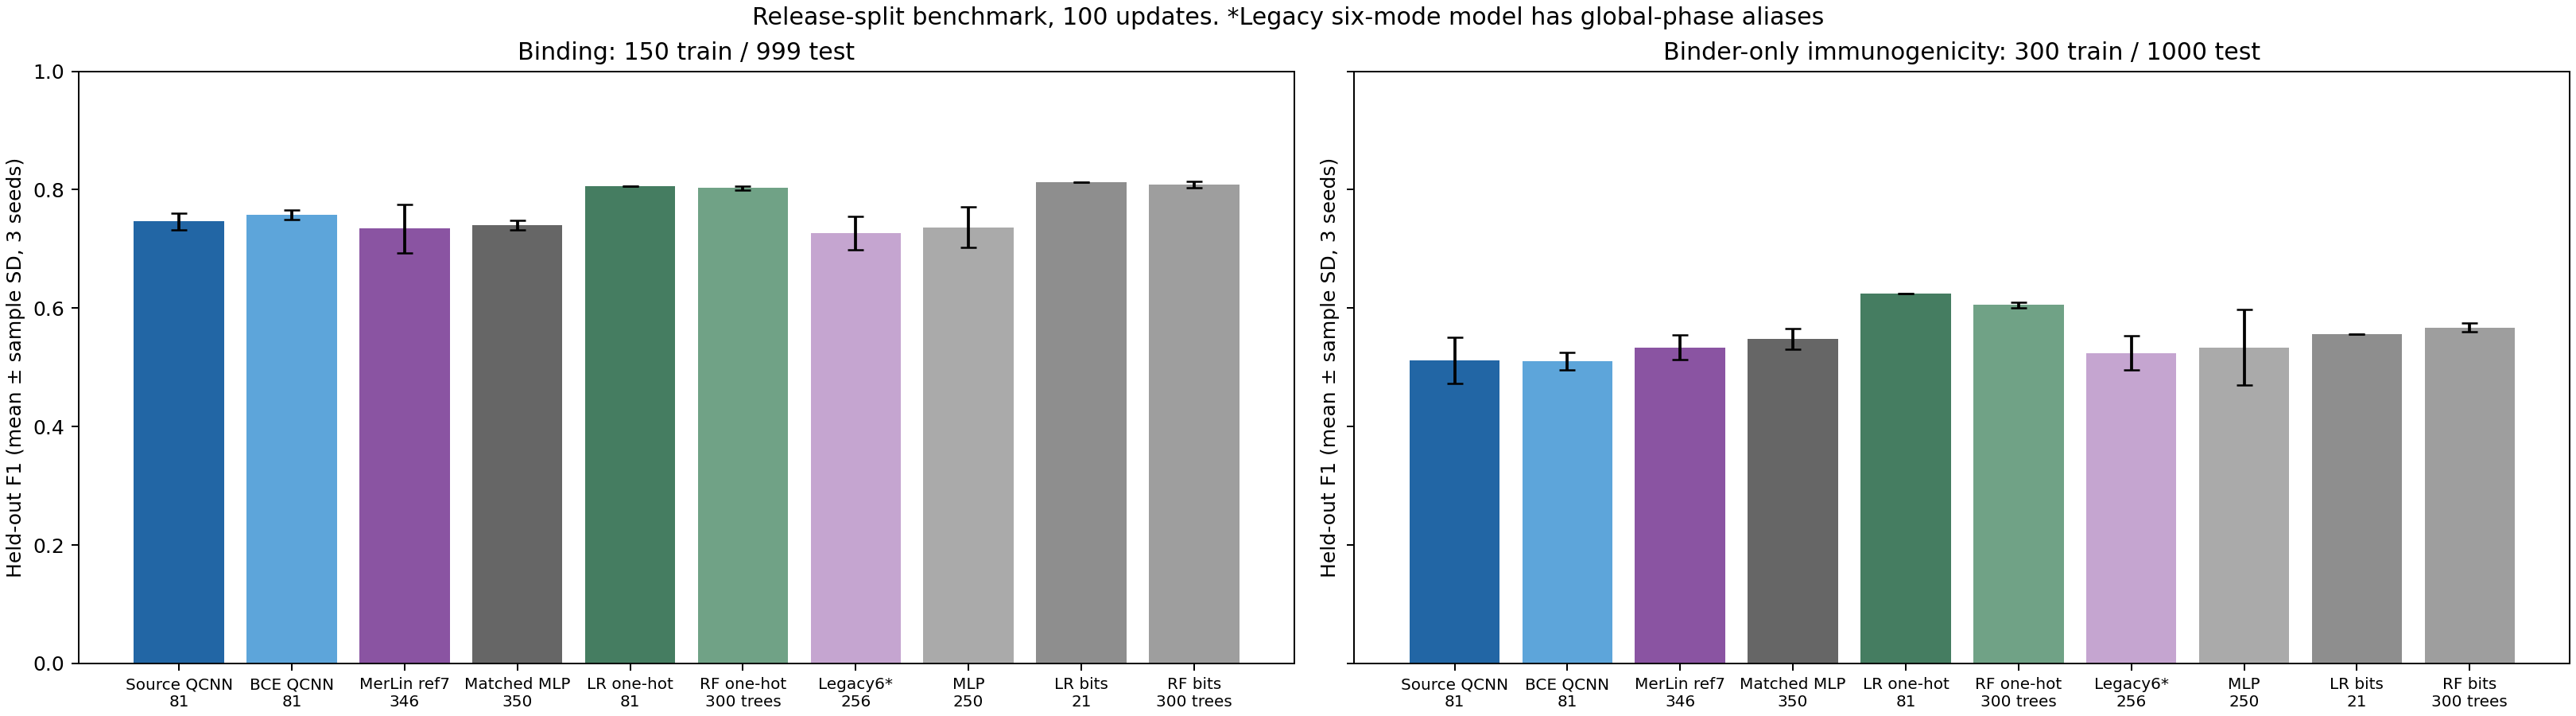

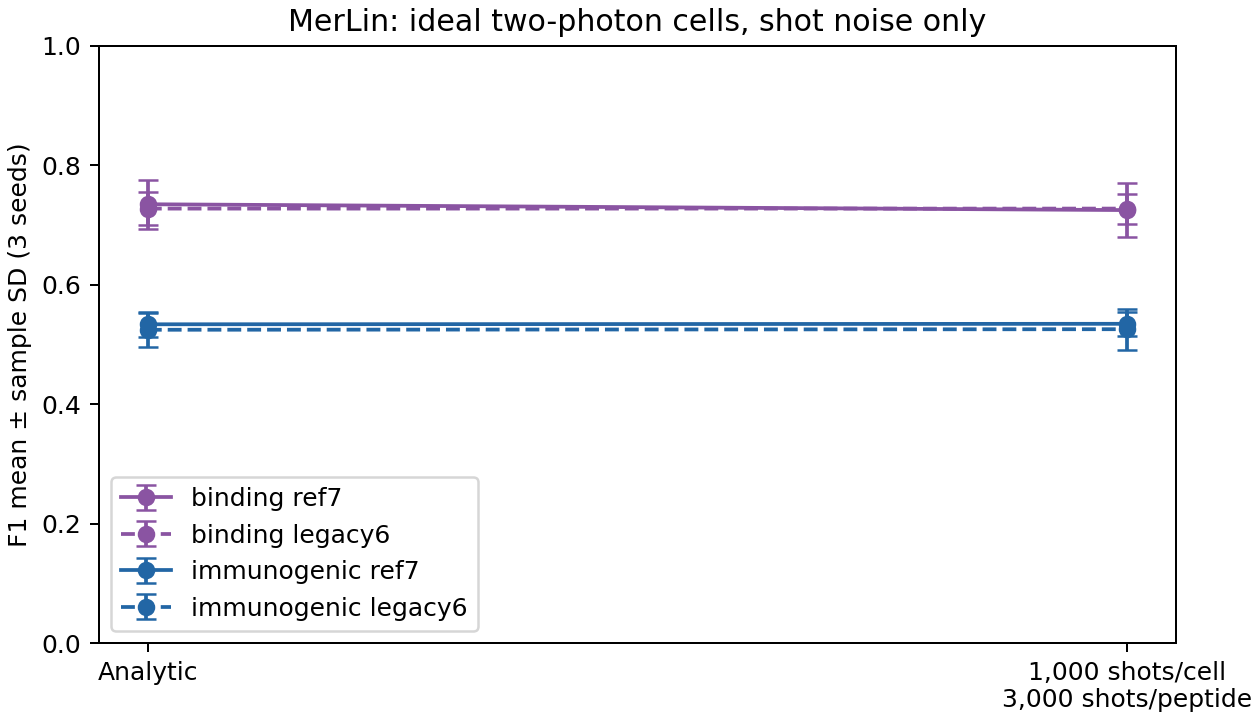

,accuracy_rank_lt2,auroc,average_precision,f1_rank_lt2,task,test_count
0,0.877878,0.956048,0.960030,0.867102,binding,999
1,0.699000,0.761068,0.703960,0.684155,mixed,1000
2,0.375000,0.334230,0.436068,0.505929,immunogenic,1000


In [6]:
from IPython.display import Image, display

display(Image(filename=str(PROJECT / 'results' / 'performance.png')))
display(Image(filename=str(PROJECT / 'results' / 'finite_shots.png')))
pd.DataFrame(report['affinity_diagnostic']['rows'])


## Trained two-head AND predictor

This cell trains the seed-49 reference heads (100 updates each, about a minute on CPU) through the shared runtime, then restores them from their checkpoints. A peptide is predicted positive only when both the binding and the binder-only immunogenicity heads are positive. The outputs are not calibrated joint probabilities.

In [7]:
import contextlib
import io

from lib.inference import QCHIPP
from runtime_lib import run_from_project

notebook_cwd = Path.cwd()
heads = {}
for task in ('binding', 'immunogenic'):
    # Per-epoch logs go to each run's run.log; keep them out of the notebook.
    with contextlib.redirect_stderr(io.StringIO()):
        heads[task] = run_from_project(
            PROJECT,
            [
                '--config', f'configs/{task}_merlin_reference.json',
                '--outdir', str(PROJECT / 'outdir' / 'notebook_heads' / task),
            ],
        )
    os.chdir(notebook_cwd)
    print(task, 'checkpoint:', heads[task].relative_to(PROJECT).as_posix())

pipeline = QCHIPP(heads['binding'], heads['immunogenic'])
peptides = populations['binding']['test']['peptides'][:4]
pd.DataFrame({'peptide': peptides, **pipeline.predict(peptides)})


binding checkpoint: outdir/notebook_heads/binding/run_20261005-112541


immunogenic checkpoint: outdir/notebook_heads/immunogenic/run_20261005-112607


,peptide,binding_probability,immunogenic_probability,positive
0,AAAAGWQTL,0.025769,0.074058,False
1,AAAGDKLSL,0.951989,0.109875,False
2,AAFAHFPEL,0.042113,0.872304,False
3,AAITDAAVA,0.042681,0.915082,False


## Reproducing the comparison

From the repository root:

```bash
python implementation.py --paper QCHIPP --config configs/binding_merlin_reference.json
python papers/QCHIPP/utils/run_comparison.py --epochs 100 --seeds 49 50 51 \
    --models merlin_reference classical_reference \
    --output papers/QCHIPP/outdir/comparison_reference
python papers/QCHIPP/utils/render_results.py
```

The full comparison is not launched from this notebook.